# CBIS-DDSM, Notebook 1 (DICOM source)

Rebuilds the Notebook 1 outputs from the original TCIA DICOM files.
- The image set, class labels and patient ids, tight-crop rule, the resolution cap, the multiscale CLAHE, the trimap rule and every other setting in, stays the sane. 
- The pixel source: DICOM crop and ROI mask from TCIA, series UIDs taken from the stored selection, are what changed. Everything is written to a new Drive folder.

In [ ]:
!pip install -q pydicom tcia_utils opencv-python scikit-learn tqdm

import os, json, random, warnings, time, glob, shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
import pydicom
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

OLD_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v2"         
NEW_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom"    
DICOM_DIR = "/content/dicom_ddsm"                                     

CONFIG = json.load(open(os.path.join(OLD_ROOT, "config.json")))
assert CONFIG.get("ROI_MAX_SIZE"), "ROI_MAX_SIZE missing in the v2 config"
DIR_MAP = {"OUTPUTS_DIR": "outputs", "PREPROCESSED_DIR": "preprocessed", "TRIMAPS_DIR": "trimaps", "ALPHAS_DIR": "alpha_maps",
           "MODELS_DIR": "models", "RESULTS_DIR": "results", "LOGS_DIR": "logs", "FIGURES_DIR": "figures"}
CONFIG["DRIVE_ROOT"] = NEW_ROOT
for var, folder in DIR_MAP.items():
    CONFIG[var] = os.path.join(NEW_ROOT, folder); os.makedirs(CONFIG[var], exist_ok=True)
CONFIG["ALPHA_MAPS_DIR"] = CONFIG["ALPHAS_DIR"]
CONFIG.update({"DATASET_DIR": DICOM_DIR, "DATA_SOURCE": "TCIA CBIS-DDSM DICOM (16-bit)", "KAGGLE_SLUG": None, "JPEG_DIR": None, "CSV_DIR": None, "DICOM_INFO_PATH": None})
json.dump(CONFIG, open(os.path.join(NEW_ROOT, "config.json"), "w"), indent=2)
globals().update(CONFIG)
SEED = CONFIG["SEED"]; random.seed(SEED); np.random.seed(SEED)
os.makedirs(DICOM_DIR, exist_ok=True)
print(f"config.json written to {NEW_ROOT}. ROI_MAX_SIZE = {ROI_MAX_SIZE}, CLAHE clip {CLAHE_CLIP_LIMIT}, tiles {CLAHE_TILE_FINE}/{CLAHE_TILE_COARSE}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.8/48.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.2/79.2 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 134.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 116.9 MB/s eta 0:00:00
Mounted at /content/drive
config.json written to /content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom. ROI_MAX_SIZE = 256, CLAHE clip 2.0, tiles [8, 8]/[16, 16]


## 1. Selection (same images as the Kaggle run)

In [ ]:
old_df = pd.read_csv(os.path.join(OLD_ROOT, "results", "final_df_loaded.csv"))
assert old_df['image_id'].is_unique
fold = lambda p: os.path.basename(os.path.dirname(str(p)))
old_df['crop_uid'], old_df['mask_uid'] = old_df['crop_path'].map(fold), old_df['mask_path'].map(fold)
NEED = sorted(set(old_df['crop_uid']) | set(old_df['mask_uid']))
print(f"{len(old_df)} images, {old_df['patient_id'].nunique()} patients, {len(NEED)} DICOM series to download")
print(old_df['class'].value_counts().to_string())
print("crop and mask in the same series for", f"{(old_df['crop_uid'] == old_df['mask_uid']).mean() * 100:.1f}% of images")


1067 images, 611 patients, 1067 DICOM series to download
class
SPIC    362
MISC    355
CIRC    350
crop and mask in the same series for 100.0% of images


## 2. Download the DICOM series 

In [3]:
from tcia_utils import nbia

def series_files(uid):
    return sorted(f for f in glob.glob(os.path.join(DICOM_DIR, uid, '**', '*'), recursive=True) if os.path.isfile(f))
def have(uid): return len(series_files(uid)) >= 1

free_gb = shutil.disk_usage('/content').free / 1e9
todo_all = [u for u in NEED if not have(u)]
print(f"free disk {free_gb:.0f} GB; {len(todo_all)} of {len(NEED)} series still to download (about 12 GB in total)")
assert free_gb > 20 or not todo_all, "not enough free disk on /content; restart the runtime or free space"
t0 = time.time(); BATCH = 100
for b in range(0, len(todo_all), BATCH):
    chunk = todo_all[b:b + BATCH]
    nbia.downloadSeries(chunk, input_type="list", path=DICOM_DIR, max_workers=8)
    print(f"batch {b // BATCH + 1}/{(len(todo_all) + BATCH - 1) // BATCH} done | {(time.time() - t0) / 60:.1f} min")
for attempt in (1, 2):
    todo = [u for u in NEED if not have(u)]
    if not todo: break
    print(f"retry {attempt}: {len(todo)} series"); nbia.downloadSeries(todo, input_type="list", path=DICOM_DIR, max_workers=4)
MISSING = [u for u in NEED if not have(u)]
size_gb = sum(os.path.getsize(f) for u in NEED for f in series_files(u)) / 1e9
print(f"\nDownloaded {len(NEED) - len(MISSING)} / {len(NEED)} series ({size_gb:.1f} GB). Missing: {len(MISSING)}")


free disk 75 GB; 1067 of 1067 series still to download (about 12 GB in total)
batch 1/11 done | 0.4 min
batch 2/11 done | 0.6 min


ERROR:tcia_utils.nbia:Exception during download for series 1.3.6.1.4.1.9590.100.1.2.179492302212251367920634197780655644337: HTTPSConnectionPool(host='nbia.cancerimagingarchive.net', port=443): Max retries exceeded with url: /nbia-api/services/v4/getImage?NewFileNames=Yes&SeriesInstanceUID=1.3.6.1.4.1.9590.100.1.2.179492302212251367920634197780655644337 (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7accd12bf110>, 'Connection to nbia.cancerimagingarchive.net timed out. (connect timeout=None)'))


batch 3/11 done | 2.9 min
batch 4/11 done | 3.2 min
batch 5/11 done | 3.5 min
batch 6/11 done | 3.8 min
batch 7/11 done | 4.1 min
batch 8/11 done | 4.4 min
batch 9/11 done | 4.6 min
batch 10/11 done | 4.9 min


ERROR:tcia_utils.nbia:Exception during download for series 1.3.6.1.4.1.9590.100.1.2.90509059711545836109239433043334788481: HTTPSConnectionPool(host='nbia.cancerimagingarchive.net', port=443): Max retries exceeded with url: /nbia-api/services/v4/getImage?NewFileNames=Yes&SeriesInstanceUID=1.3.6.1.4.1.9590.100.1.2.90509059711545836109239433043334788481 (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7accd12bf750>, 'Connection to nbia.cancerimagingarchive.net timed out. (connect timeout=None)'))


batch 11/11 done | 7.2 min
retry 1: 2 series

Downloaded 1067 / 1067 series (18.6 GB). Missing: 0


## 3. Crops, masks, CLAHE, trimaps

In [ ]:
ROI_MARGIN_FACTOR, ROI_MARGIN_MIN_PX = 0.7, 40         
def read_arrays(uid):
    out = []
    for f in series_files(uid):
        try:
            ds = pydicom.dcmread(f); a = ds.pixel_array
        except Exception:
            continue
        if a.ndim == 3: a = a[..., 0]
        if str(getattr(ds, 'PhotometricInterpretation', '')).strip() == 'MONOCHROME1': a = (a.max() - a).astype(a.dtype)
        out.append(a)
    return out
def n_levels(a): return int(len(np.unique(a[::2, ::2])))
def split_crop_mask(arrs):
    """The crop and its ROI mask: the mask has only a few distinct grey levels."""
    if len(arrs) != 2: return None
    lv = [n_levels(a) for a in arrs]
    if lv[0] == lv[1]: return None
    m = int(np.argmin(lv)); return arrs[1 - m], arrs[m]
def tighten_to_mask(crop, mbin):
    ys, xs = np.where(mbin)
    if len(ys) == 0: return None
    r0, r1, c0, c1 = ys.min(), ys.max(), xs.min(), xs.max()
    margin = max(int(round(ROI_MARGIN_FACTOR * max(r1 - r0 + 1, c1 - c0 + 1))), ROI_MARGIN_MIN_PX)
    h, w = crop.shape
    R0, R1, C0, C1 = max(0, r0 - margin), min(h, r1 + margin + 1), max(0, c0 - margin), min(w, c1 + margin + 1)
    return crop[R0:R1, C0:C1], mbin[R0:R1, C0:C1]
def cap_size(img, interp):
    h, w = img.shape[:2]; ls = max(h, w)
    if ls <= ROI_MAX_SIZE: return img
    s = ROI_MAX_SIZE / ls
    return cv2.resize(img, (int(round(w * s)), int(round(h * s))), interpolation=interp)
def to_u16(a):
    a = a.astype(np.float32); lo, hi = float(a.min()), float(a.max())
    return np.zeros(a.shape, np.uint16) if hi <= lo else ((a - lo) / (hi - lo) * 65535.0).astype(np.uint16)
def multiscale_clahe_u16(img16):
    f = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_FINE)).apply(img16)
    c = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_COARSE)).apply(img16)
    return (f.astype(np.float32) + c.astype(np.float32)) / 2.0
def normalize01(a):
    a = a.astype(np.float32); lo, hi = a.min(), a.max()
    return (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a)
def make_trimap_from_mask(mask, erode_iters=None, dilate_iters=None):       # identical to the Kaggle Notebook 1
    ei = TRIMAP_ERODE_ITERS if erode_iters is None else erode_iters; di = TRIMAP_DILATE_ITERS if dilate_iters is None else dilate_iters
    m = (mask > 127).astype(np.uint8); k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    trimap = np.full(mask.shape, 128, np.uint8)
    trimap[cv2.dilate(m, k, iterations=di) == 0] = 0; trimap[cv2.erode(m, k, iterations=ei) == 1] = 255
    if (trimap == 255).sum() < 10: trimap[m == 1] = 255
    return trimap

preprocessed_results, meta_rows, FAILED, DCM_INFO, RAWS = {}, [], [], {}, {}
for _, row in tqdm(old_df.iterrows(), total=len(old_df), desc="DICOM -> ROI"):
    iid = row['image_id']
    arrs = read_arrays(row['crop_uid']) + ([] if row['mask_uid'] == row['crop_uid'] else read_arrays(row['mask_uid']))
    pair = split_crop_mask(arrs)
    if pair is None: FAILED.append({'image_id': iid, 'reason': 'could not separate crop and mask'}); continue
    crop, mask = pair
    if mask.shape != crop.shape: mask = cv2.resize(mask, (crop.shape[1], crop.shape[0]), interpolation=cv2.INTER_NEAREST)
    mbin = mask > (mask.max() / 2.0)
    if mbin.sum() < 20: FAILED.append({'image_id': iid, 'reason': 'empty mask'}); continue
    tc, tm = tighten_to_mask(crop.astype(np.float32), mbin)
    c2 = cap_size(tc, cv2.INTER_AREA); m2 = cap_size(tm.astype(np.uint8) * 255, cv2.INTER_NEAREST)
    if m2.shape != c2.shape: m2 = cv2.resize(m2, (c2.shape[1], c2.shape[0]), interpolation=cv2.INTER_NEAREST)
    roi = normalize01(multiscale_clahe_u16(to_u16(c2)))
    trimap = make_trimap_from_mask(m2); gt_mask = (m2 > 127).astype(np.uint8) * 255
    preprocessed_results[iid] = {'roi': roi, 'trimap': trimap, 'gt_mask': gt_mask}
    DCM_INFO[iid] = {'dtype': str(crop.dtype), 'levels': n_levels(crop)}
    RAWS[iid] = c2.astype(np.float32)
    meta_rows.append({'image_id': iid, 'class': row['class'], 'lesion_key': row['lesion_key'], 'view': row['view'], 'roi_h': roi.shape[0], 'roi_w': roi.shape[1],
                      'fg_fraction': float((trimap == 255).mean()), 'mask_fraction': float((gt_mask > 0).mean())})
metadata_df = pd.DataFrame(meta_rows)
print(f"\nPreprocessed {len(preprocessed_results)} / {len(old_df)} images; failed {len(FAILED)}")
if FAILED:
    print(FAILED[:10]); print("WARNING: a missing image changes the patient-grouped split built in Notebook 2.")
with open(os.path.join(LOGS_DIR, "failed_cases_dicom.json"), 'w') as f: json.dump(FAILED, f, indent=2)
print(f"ROI size range {metadata_df[['roi_h', 'roi_w']].min().min()} to {metadata_df[['roi_h', 'roi_w']].max().max()} px; "
      f"mean trimap foreground fraction {metadata_df['fg_fraction'].mean():.3f}")


DICOM -> ROI: 100%|██████████| 1067/1067 [03:30<00:00,  5.06it/s]



Preprocessed 1067 / 1067 images; failed 0
ROI size range 45 to 256 px; mean trimap foreground fraction 0.021


## 4. Comparison with the Kaggle-based ROIs

same shape as the Kaggle ROI on 100.0% of images
ROI correlation DICOM vs JPEG pipeline: median 0.920, 5th percentile 0.586
mask Dice DICOM vs Kaggle:            median 1.0000, 5th percentile 1.0000
DICOM crop grey levels per image: median 994 (8-bit JPEG would give at most 256); dtypes {'uint16': 1067}


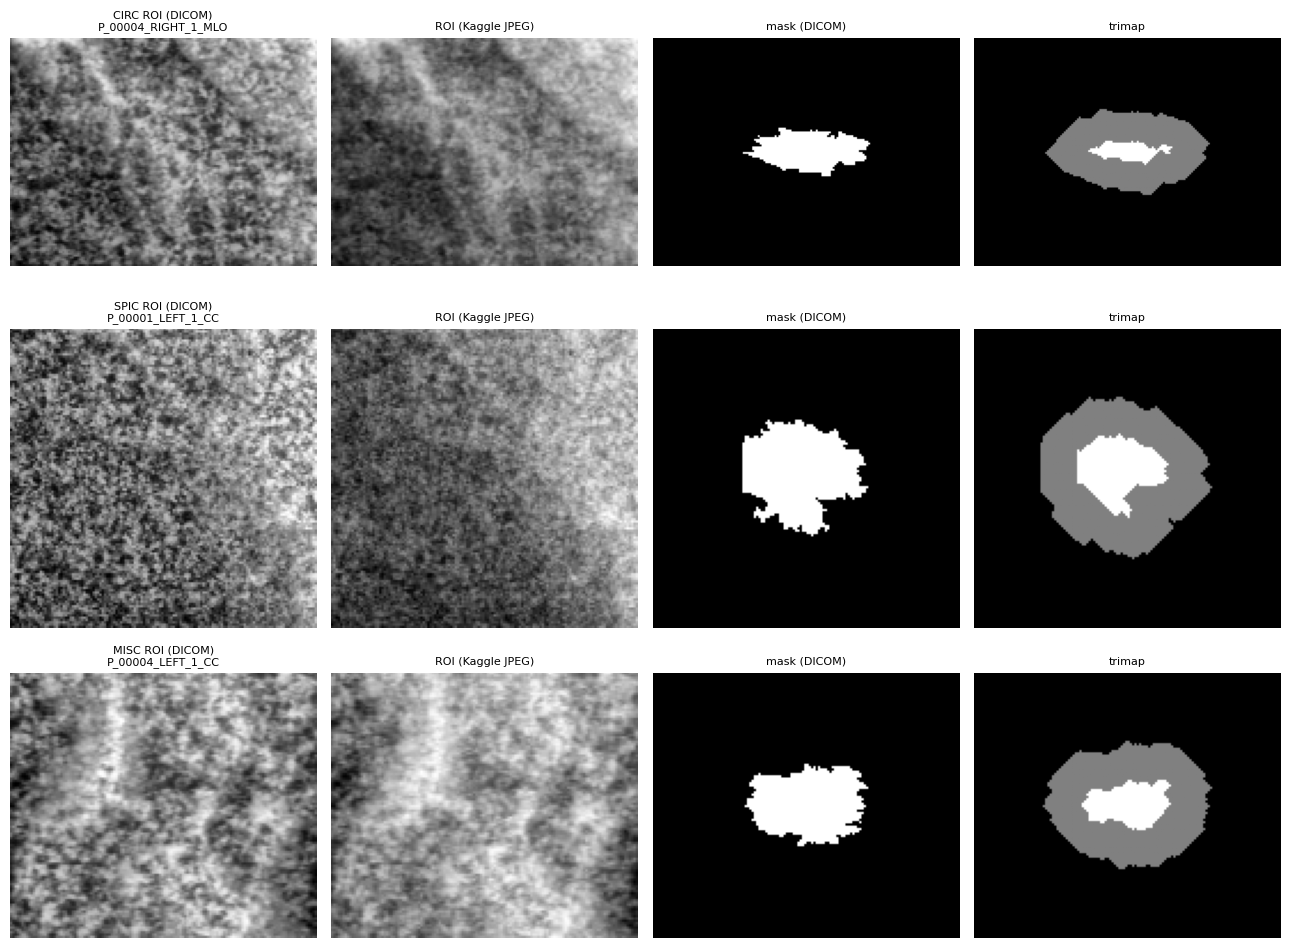

In [ ]:
old_roi = np.load(os.path.join(OLD_ROOT, "preprocessed", "rois.npz")); old_gt = np.load(os.path.join(OLD_ROOT, "preprocessed", "gt_masks.npz"))
same_shape, corr, dsc = [], [], []
for iid, d in preprocessed_results.items():
    o, g = old_roi[iid], old_gt[iid]; ok = o.shape == d['roi'].shape; same_shape.append(ok)
    if ok:
        corr.append(float(np.corrcoef(o.ravel(), d['roi'].ravel())[0, 1]))
        a, b = d['gt_mask'] > 127, g > 127; dsc.append(float(2 * (a & b).sum() / max(a.sum() + b.sum(), 1)))
print(f"same shape as the Kaggle ROI on {np.mean(same_shape) * 100:.1f}% of images")
print(f"ROI correlation DICOM vs JPEG pipeline: median {np.median(corr):.3f}, 5th percentile {np.percentile(corr, 5):.3f}")
print(f"mask Dice DICOM vs Kaggle:            median {np.median(dsc):.4f}, 5th percentile {np.percentile(dsc, 5):.4f}")
lv = np.array([v['levels'] for v in DCM_INFO.values()]); print(f"DICOM crop grey levels per image: median {int(np.median(lv))} (8-bit JPEG would give at most 256); dtypes {pd.Series([v['dtype'] for v in DCM_INFO.values()]).value_counts().to_dict()}")

ids = [i for i in old_df['image_id'] if i in preprocessed_results]
picks = {c: next(i for i in ids if old_df.set_index('image_id').loc[i, 'class'] == c) for c in TARGET_CLASSES}
fig, axes = plt.subplots(len(picks), 4, figsize=(13, 3.3 * len(picks)))
for r, (cls, iid) in enumerate(picks.items()):
    d = preprocessed_results[iid]
    axes[r, 0].imshow(d['roi'], cmap='gray'); axes[r, 0].set_title(f"{cls} ROI (DICOM)\n{iid[:28]}", fontsize=8)
    axes[r, 1].imshow(old_roi[iid], cmap='gray'); axes[r, 1].set_title("ROI (Kaggle JPEG)", fontsize=8)
    axes[r, 2].imshow(d['gt_mask'], cmap='gray'); axes[r, 2].set_title("mask (DICOM)", fontsize=8)
    axes[r, 3].imshow(d['trimap'], cmap='gray'); axes[r, 3].set_title("trimap", fontsize=8)
    for c in range(4): axes[r, c].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "section4_sample_verification_dicom.png"), dpi=140, bbox_inches='tight'); plt.show()


## 5. Save

In [6]:
np.savez_compressed(os.path.join(PREPROCESSED_DIR, "rois.npz"), **{k: v['roi'] for k, v in preprocessed_results.items()})
np.savez_compressed(os.path.join(TRIMAPS_DIR, "trimaps.npz"), **{k: v['trimap'] for k, v in preprocessed_results.items()})
np.savez_compressed(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"), **{k: v['gt_mask'] for k, v in preprocessed_results.items()})
np.savez_compressed(os.path.join(PREPROCESSED_DIR, "raw_crops.npz"), **RAWS)
metadata_df.to_csv(os.path.join(PREPROCESSED_DIR, "preprocessing_metadata.csv"), index=False)
final_df_loaded = old_df[old_df['image_id'].isin(preprocessed_results)].reset_index(drop=True)          # same rows, same order as v2
final_df_loaded['dicom_series_uid'] = final_df_loaded['crop_uid']
final_df_loaded['crop_path'] = final_df_loaded['crop_uid'].map(lambda u: os.path.join(DICOM_DIR, u, 'crop'))   # folder name = series UID
final_df_loaded['mask_path'] = final_df_loaded['mask_uid'].map(lambda u: os.path.join(DICOM_DIR, u, 'mask'))
final_df_loaded.drop(columns=['crop_uid', 'mask_uid']).to_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"), index=False)
print("Saved rois.npz, trimaps.npz, gt_masks.npz, preprocessing_metadata.csv, final_df_loaded.csv to", NEW_ROOT)


Saved rois.npz, trimaps.npz, gt_masks.npz, preprocessing_metadata.csv, final_df_loaded.csv to /content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom


In [7]:
def verify_nb1_dicom():
    n_old = len(old_df); n_new = len(preprocessed_results)
    checks = {
        "all images of the Kaggle selection processed (else the split changes)": n_new == n_old,
        "image ids are a subset of the Kaggle selection, same order"           : list(final_df_loaded['image_id']) == [i for i in old_df['image_id'] if i in preprocessed_results],
        "DICOM crops are 16-bit with > 256 grey levels (median)"               : float(np.median(lv)) > 256,
        "ROI in [0,1]"                                                         : all(v['roi'].min() >= 0 and v['roi'].max() <= 1 for v in preprocessed_results.values()),
        "trimap has 3 levels and a foreground"                                 : all(set(np.unique(v['trimap'])) <= {0, 128, 255} and (v['trimap'] == 255).sum() > 0 for v in preprocessed_results.values()),
        "resolution capped"                                                    : metadata_df[['roi_h', 'roi_w']].max().max() <= ROI_MAX_SIZE,
        "same shape as the Kaggle ROI on >= 95% of images"                     : np.mean(same_shape) >= 0.95,
        "mask Dice vs Kaggle >= 0.98 (median)"                                 : np.median(dsc) >= 0.98,
        "saved to the new Drive folder"                                        : os.path.exists(os.path.join(PREPROCESSED_DIR, "rois.npz")) and os.path.exists(os.path.join(RESULTS_DIR, "final_df_loaded.csv")),
        "raw 16-bit crops saved for every image"                               : os.path.exists(os.path.join(PREPROCESSED_DIR, "raw_crops.npz")),
    }
    print("=" * 66); print("NOTEBOOK 1 (DICOM) VERIFICATION"); print("=" * 66); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if v else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 66); print("Next: run Notebooks 2-5 from the *_dicom copies (they point to the new folder)." if ok else "Review failures first."); return ok
verify_nb1_dicom()


NOTEBOOK 1 (DICOM) VERIFICATION
  OK    all images of the Kaggle selection processed (else the split changes)
  OK    image ids are a subset of the Kaggle selection, same order
  OK    DICOM crops are 16-bit with > 256 grey levels (median)
  OK    ROI in [0,1]
  OK    trimap has 3 levels and a foreground
  OK    resolution capped
  OK    same shape as the Kaggle ROI on >= 95% of images
  OK    mask Dice vs Kaggle >= 0.98 (median)
  OK    saved to the new Drive folder
  OK    raw 16-bit crops saved for every image
Next: run Notebooks 2-5 from the *_dicom copies (they point to the new folder).


True